In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
## Metrics
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.metrics import f1_score, precision_score, classification_report
from sklearn.metrics import accuracy_score
## Model Selections
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import  GridSearchCV
## Linear Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.linear_model import LogisticRegression
## Models
from sklearn.svm import SVC
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier
## Ensemble
from sklearn.ensemble import VotingClassifier, BaggingRegressor, VotingRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import StackingClassifier
## Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
## Pipiline
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('epi_r.csv')
ingridien = pd.read_csv('DSB12_Ингридиентные столбцы.csv')
ingridien = ingridien.query("is_ingridien == 1")['title'].tolist()
df_ingridien = df[['rating', *ingridien]]
y = df_ingridien['rating']
X = df_ingridien.iloc[:, 1:]
corr =X.corr()

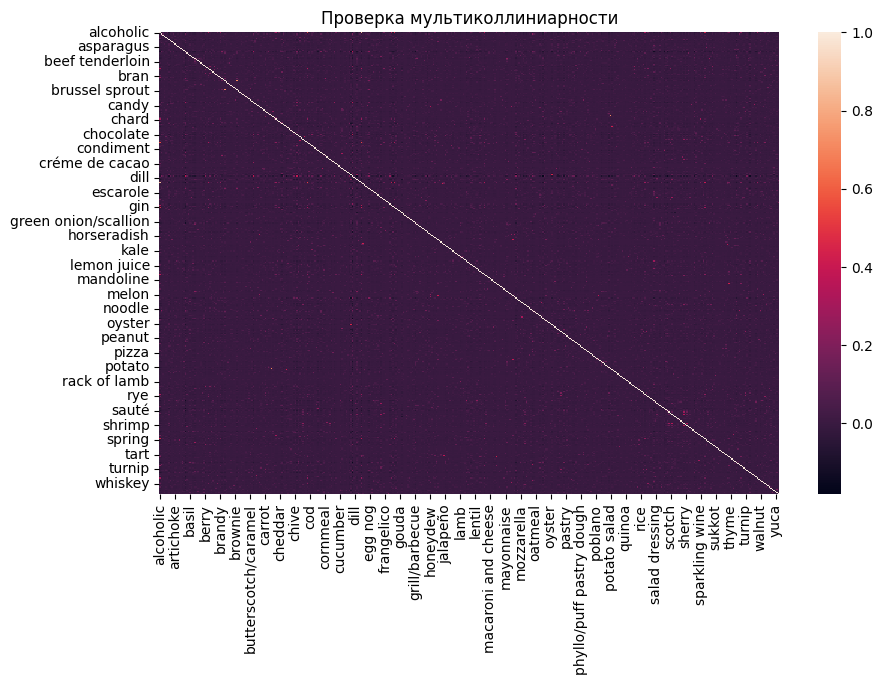

In [6]:
fig, ax =plt.subplots(figsize=(10,6))
ax.set_title('Проверка мультиколлиниарности')
sns.heatmap(corr);

In [7]:
# Распределение целевой переменной
y.value_counts(normalize=True)

rating
4.375    0.399910
3.750    0.257780
5.000    0.135597
0.000    0.091562
3.125    0.074257
2.500    0.026531
1.250    0.008179
1.875    0.006184
Name: proportion, dtype: float64

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21, stratify=y)

# Линейные модели

In [9]:
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5),
    "KNeighborsRegressor": KNeighborsRegressor(),
    "BaggingRegressor": BaggingRegressor(LinearRegression(), n_estimators=5),
    "VotingRegressor": VotingRegressor([
        ("LiniarRegression", LinearRegression()),
        ("Ridge", Ridge(alpha=1.0)),
        ("KNN", KNeighborsRegressor())
    ])
}
result = {}

In [10]:
for name, model in tqdm(models.items()):
    pipe = Pipeline([
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)

    result[name] = {"R2": r2, "RMSE": rmse}

100%|██████████| 7/7 [00:04<00:00,  1.71it/s]


#### Наивное предсказание (по среднему результату)

In [11]:
naiv_pred = np.full(y_test.shape, y_test.mean())
r2_naiv = r2_score(y_test, naiv_pred)
rmse_naiv = root_mean_squared_error(y_test, naiv_pred)
result['Наивное предсказание'] = {"R2": r2_naiv, "RMSE": rmse_naiv}

In [12]:
pd.DataFrame(result).T.sort_values(by='RMSE').style.format('{:.4f}')

,R2,RMSE
VotingRegressor,0.1032,1.2696
Ridge,0.0929,1.2768
BaggingRegressor,0.0879,1.2803
LinearRegression,0.0859,1.2817
ElasticNet,0.0183,1.3283
Наивное предсказание,0.0000,1.3406
Lasso,-0.0000,1.3406
KNeighborsRegressor,-0.0896,1.3994


## `Вывод:` Линейные модели почти не лучше среднего предсказания R2 = 0.10, нужно пробовать нелинейные модели

# НЕлинейные модели

### Классификация

In [13]:
df_ingridien['rating_rounded'] = df_ingridien['rating'].round()
y = df_ingridien['rating_rounded']
X = df_ingridien.iloc[:, 1:-2]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

### Логистическая регрессия

In [15]:
log_reg = LogisticRegression(max_iter=1000)
param = {"C": [0.1, 1, 5],
        "solver": ['newton-cg', 'lbfgs']}
log_clf = GridSearchCV(log_reg, param_grid=param, cv=3)


log_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'solver': ['newton-cg', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : t

In [16]:
best_log_reg_predict = log_clf.best_estimator_.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, best_log_reg_predict):.5f}')
print(f'F1 is - {f1_score(y_test, best_log_reg_predict, average='weighted'):.5f}')

Accuracy is - 0.66991
F1 is - 0.56573


### SVM

In [17]:
svc = SVC()
svc.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [18]:
svc_pred = svc.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, svc_pred):.5f}')
print(f'F1 is - {f1_score(y_test, svc_pred, average='weighted'):.5f}')

Accuracy is - 0.67215
F1 is - 0.56322


### DesicionTree

In [26]:
tree = DecisionTreeClassifier(max_depth=10, random_state=21)
tree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",21
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

In [27]:
tree_pred = tree.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, tree_pred):.5f}')
print(f'F1 is - {f1_score(y_test, tree_pred, average='weighted'):.5f}')

Accuracy is - 0.66517
F1 is - 0.56653


In [28]:
param = {
    'criterion': ['gini', 'entropy'],
    'max_depth': range(4, 50, 2),
    'class_weight': [None, 'balanced'],
    'random_state': [21]
}
tree_clf = GridSearchCV(DecisionTreeClassifier(), param_grid=param, n_jobs=-1, cv=5)
tree_clf.fit(X_train, y_train)
tree_pred_tune = tree_clf.best_estimator_.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, tree_pred_tune):.5f}')
print(f'F1 is - {f1_score(y_test, tree_pred_tune, average='weighted'):.5f}')

Accuracy is - 0.66442
F1 is - 0.55708


### RandomForest

In [12]:
param = {
    'n_estimators': range(10, 101, 10),
    'criterion': ['gini', 'entropy'],
    'random_state': [21],
    'max_depth': range(4, 17, 4)
}
forest_clf = GridSearchCV(RandomForestClassifier(), param_grid=param, n_jobs=-1, cv=5)
forest_clf.fit(X_train, y_train)
best_forest = forest_clf.best_estimator_.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, best_forest):.5f}')
print(f'F1 is - {f1_score(y_test, best_forest, average='weighted'):.5f}')

Accuracy is - 0.79980
F1 is - 0.72551


In [30]:
print(np.unique_counts(y_test))
naiv_pred = np.array([4.] * len(y_test))
print('Проверка наивного предсказания по самому популярному классу')
print(f'Accuracy is - {accuracy_score(y_test, naiv_pred):.5f}')
print(f'F1 is - {f1_score(y_test, naiv_pred, average='weighted'):.5f}')

UniqueCountsResult(values=array([0., 1., 2., 3., 4., 5.]), counts=array([ 367,   33,  131,  298, 2638,  544]))
Проверка наивного предсказания по самому популярному классу
Accuracy is - 0.65769
F1 is - 0.52188


### Бинаризация целевой переменной на 3 класса (bad(0, 1), so-so(2, 3), great(4, 5))

In [30]:
df_ingridien.head()

,rating,alcoholic,almond,amaretto,anchovy,anise,aperitif,appetizer,apple,apple juice,...,white wine,wild rice,wine,wok,yellow squash,yogurt,yuca,zucchini,snack,rating_rounded
0,2.500,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
1,4.375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
2,3.750,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0
3,5.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0
4,3.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0


In [20]:
cuted_rating = pd.cut(df_ingridien['rating_rounded'], bins=[0, 1, 3, 5], labels=['bad', 'so-so', 'great'], include_lowest=True)
cuted_rating.value_counts()

rating_rounded
great    15907
so-so     2145
bad       2000
Name: count, dtype: int64

In [ ]:
#encoder = LabelEncoder()
#encoded_rating = encoder.fit_transform(cuted_rating)
#encoder.classes_

array(['bad', 'great', 'so-so'], dtype=object)

In [ ]:
#df_ingridien['encoded_rating'] = encoded_rating

In [21]:
df_ingridien['encoded_rating'] = cuted_rating.str.replace({'bad': '0', 'so-so': '1', 'great': '2'}).astype(int)

In [22]:
y = df_ingridien['encoded_rating']
X = df_ingridien.iloc[:, 1:-2]

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=21)

### Бинаризация целевой переменной на 2 класса bad(0 - 3), great (4 - 5)

In [24]:
cuted_rating_2_class = pd.cut(df_ingridien['rating_rounded'], bins=[0, 3, 5], labels=['bad', 'great'], include_lowest=True)
df_ingridien['encoded_rating_2_class'] = cuted_rating_2_class.str.replace(({'bad': '0', 'great': '1'})).astype(int)

In [25]:
y = df_ingridien['encoded_rating_2_class']
X = df_ingridien.iloc[:, 1:-3]

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21, stratify=y)
X_train, X_valid, y_train, y_valid = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=21)

### Снова Логистическая регрессия

In [38]:
log_reg2 = LogisticRegression(max_iter=1000, random_state=21)
log_reg2.fit(X_train, y_train)
log_reg2_pred = log_reg2.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, log_reg2_pred):.5f}')
print(f'F1 is - {f1_score(y_test, log_reg2_pred, average='weighted'):.5f}')

Accuracy is - 0.80030
F1 is - 0.73536


### Наивное предсказание по самому популярному классу

In [54]:
y_test.value_counts()

encoded_rating_2_class
1    3182
0     829
Name: count, dtype: int64

In [56]:
naiv_pred = np.array([1] * len(y_test))
print('Проверка наивного предсказания по самому популярному классу')
print(f'Accuracy is - {accuracy_score(y_test, naiv_pred):.5f}')
print(f'F1 is - {f1_score(y_test, naiv_pred):.5f}')

Проверка наивного предсказания по самому популярному классу
Accuracy is - 0.79332
F1 is - 0.88475


### Случайный лес

In [58]:
forest_clf2 = GridSearchCV(RandomForestClassifier(), param_grid=param, n_jobs=-1, cv=5)
forest_clf2.fit(X_train, y_train)
forest2_pred = forest_clf2.best_estimator_.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, forest2_pred):.5f}')
print(f'F1 is - {f1_score(y_test, forest2_pred, average='weighted'):.5f}')

Accuracy is - 0.80180
F1 is - 0.73386


### Бэггинг

In [63]:
bag_clf = BaggingClassifier(LogisticRegression(), n_estimators=10, n_jobs=-1, random_state=21)
bag_clf.fit(X_train, y_train)
bag_pred = bag_clf.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, bag_pred):.5f}')
print(f'F1 is - {f1_score(y_test, bag_pred, average='weighted'):.5f}')
print(classification_report(y_test, bag_pred))

Accuracy is - 0.80080
F1 is - 0.74684
              precision    recall  f1-score   support

           0       0.58      0.13      0.21       829
           1       0.81      0.98      0.89      3182

    accuracy                           0.80      4011
   macro avg       0.70      0.55      0.55      4011
weighted avg       0.76      0.80      0.75      4011



### Стэккинг

In [64]:
stack_clf = StackingClassifier([
    ('svm', SVC()),
    ('tree', DecisionTreeClassifier()),
    ('forest', RandomForestClassifier())
], final_estimator=LogisticRegression(), n_jobs=-1)
stack_clf.fit(X_train, y_train)
stack_pred = stack_clf.predict(X_test)
print(f'Accuracy is - {accuracy_score(y_test, stack_pred):.5f}')
print(f'F1 is - {f1_score(y_test, stack_pred, average='weighted'):.5f}')
print(classification_report(y_test, stack_pred))

Accuracy is - 0.82349
F1 is - 0.78776
              precision    recall  f1-score   support

           0       0.71      0.25      0.37       829
           1       0.83      0.97      0.90      3182

    accuracy                           0.82      4011
   macro avg       0.77      0.61      0.63      4011
weighted avg       0.81      0.82      0.79      4011



## Пробуем другую метрику F1, precision

In [27]:
pipe_lr = Pipeline([('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
pipe_rf = Pipeline([('model', RandomForestClassifier(class_weight='balanced'))])
pipe_tree = Pipeline([('model', DecisionTreeClassifier())])

In [28]:
param_grid_lr = {
    'model__C': [0.1, 1, 10],
    'model__random_state': [21]
}

param_grid_rf = {
    'model__n_estimators': [10, 50, 100],
    'model__max_depth': [5, 10, None],
    'model__random_state': [21],
    'model__criterion': ['gini', 'entropy']
}

param_grid_dt = {
    'model__max_depth': [3, 5, 10],
    'model__min_samples_split': [2, 5, 10],
    'model__random_state': [21]
}

In [29]:
def train_and_evaluate(pipe, param_grid, X_train, y_train, X_valid, y_valid):
    grid = GridSearchCV(
        pipe,
        param_grid,
        scoring='f1',
        cv=5,
        n_jobs=-1
    )
    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_valid)
    f1 = f1_score(y_valid, y_pred, average='weighted')

    return best_model, f1, grid.best_params_

In [30]:
models = [
    (pipe_lr, param_grid_lr, "LogReg"),
    (pipe_tree, param_grid_dt, "DecisionTree"),
    (pipe_rf, param_grid_rf, "RandomForest")
]

result = []

In [31]:
for pipe, grid, name in tqdm(models):
    model, f1, params = train_and_evaluate(pipe, grid, X_train, y_train, X_valid, y_valid)

    result.append({
        "model": name,
        "f1": f1,
        "params": params,
        "model_obj": model
    })

result = sorted(result, key=lambda x: x['f1'], reverse=True)
best_model = result[0]['model_obj']

100%|██████████| 3/3 [00:26<00:00,  8.84s/it]


In [32]:
best_model[0]

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [33]:
y_test_pred = best_model.predict(X_test)
f1_test = f1_score(y_test, y_test_pred, average='weighted')

print("Best model:", result[0]['model'])
print("F1 (test):", f1_test)
print(classification_report(y_test, y_test_pred))

Best model: RandomForest
F1 (test): 0.7876520601547501
              precision    recall  f1-score   support

           0       0.60      0.30      0.40       829
           1       0.84      0.95      0.89      3182

    accuracy                           0.81      4011
   macro avg       0.72      0.62      0.64      4011
weighted avg       0.79      0.81      0.79      4011



In [34]:
pd.DataFrame(result)

,model,f1,params,model_obj
0,RandomForest,0.782158,"{'model__criterion': 'gini', 'model__max_depth...","((DecisionTreeClassifier(max_features='sqrt', ..."
1,DecisionTree,0.748610,"{'model__max_depth': 5, 'model__min_samples_sp...","(DecisionTreeClassifier(max_depth=5, min_sampl..."
2,LogReg,0.673435,"{'model__C': 0.1, 'model__random_state': 21}","(LogisticRegression(C=0.1, class_weight='balan..."


### VotingClassfier

In [72]:
list_models = [(model['model'], model['model_obj']) for model in result]
vote_clf = VotingClassifier(list_models, n_jobs=-1)
vote_clf.fit(X_train, y_train)
f1_vote = f1_score(y_test, vote_clf.predict(X_test), average='weighted')
precision_vote = precision_score(y_test, result[2]['model_obj'].predict(X_test), pos_label=1, average='weighted')
print(f'Precision is - {precision_vote:.5f}')
print(f'F1 is - {f1_vote:.5f}')
print(classification_report(y_test, vote_clf.predict(X_test)))

Precision is - 0.73918
F1 is - 0.77439
              precision    recall  f1-score   support

           0       0.54      0.27      0.36       829
           1       0.83      0.94      0.88      3182

    accuracy                           0.80      4011
   macro avg       0.68      0.61      0.62      4011
weighted avg       0.77      0.80      0.77      4011



In [35]:
model_final = best_model

In [36]:
test_ingrid_bad = ['saffron', 'gin', 'chile paper']
test_ingrid_good = ['bread', 'avocado', 'cheese', 'garlic']

In [37]:
def prepare_df(ingridien_list):
    test_df = pd.DataFrame([[0]*X.shape[1]], columns=X.columns)
    for ing in ingridien_list:
        if ing in test_df.columns:
            test_df[ing] = 1
    return test_df

In [38]:
test_df = prepare_df(test_ingrid_bad)

In [39]:
model_final.predict(test_df)

array([0])

In [107]:
proba = model_final.predict_proba(X_test)

In [108]:
best_t = 0
best_f1 = 0
for t in np.linspace(0.05, 0.95, 50):
    f1 = f1_score(y_test, (proba >= t).astype(int).argmax(axis=1))
    if f1 > best_f1:
        best_f1 = f1
        best_t = t
print(best_t, best_f1)

0.4908163265306122 0.8897091392292927


In [109]:
f1_score(y_test, model_final.predict(X_test))

0.8897405660377359

### Сохранение лучшей модели

In [58]:
import joblib

In [110]:
joblib.dump(model_final, '../data/model_final.pkl')

['../data/model_final.pkl']